In [ ]:
# Downloading Libraries #
!pip install matplotlib feedparser keras yfinance transformers torch scikit-learn

In [ ]:
# Importing #
import numpy as np
import pandas as pd
import datetime
import matplotlib.pyplot as plt

import yfinance as yf
import feedparser
from transformers import pipeline
import torch

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, GRU, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping
from datetime import date

In [ ]:
# Global Constants #
TICKER = "AMZN"
YEAR_RANGE = 5
MAX_RSS = 100
TIME_STEP = 50
EPOCHS = 30
BATCH_SIZE = 32
FORECAST_DAYS = 5

In [ ]:
# Prepare Data #
# RSS Feeds
rss_url = f"https://feeds.finance.yahoo.com/rss/2.0/headline?s={TICKER}&region=US&lang=en-US"
rss_feed = feedparser.parse(rss_url)

feed_title_tuples = []
feed_summary_tuples = []
for feed in rss_feed.entries[:MAX_RSS]:
  date_time = datetime.datetime(*feed.published_parsed[:6]).date()
  feed_title_tuples.append((date_time, feed.title))
  feed_summary_tuples.append((date_time, feed.summary))

feed_title_table = pd.DataFrame(feed_title_tuples, columns = ['Date', 'Title'])
feed_summary_table = pd.DataFrame(feed_summary_tuples, columns = ['Date', 'Summary'])

# Ticker Close
tickers_raw = yf.download(TICKER, period = f"{YEAR_RANGE}y")[['Close']].dropna().reset_index()

if isinstance(tickers_raw.columns, pd.MultiIndex) and tickers_raw.columns.nlevels >= 2:
  tickers_raw.columns = tickers_raw.columns.droplevel(1)

tickers_raw.columns = ['Date', 'Close']
tickers_raw['Date'] = pd.to_datetime(tickers_raw['Date']).dt.date

/tmp/ipykernel_982/3469494571.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  tickers_raw = yf.download(TICKER, period = f"{YEAR_RANGE}y")[['Close']].dropna().reset_index()
[*********************100%***********************]  1 of 1 completed


In [ ]:
# Sentiment Analysis #
if torch.cuda.is_available():
  device = 0
else:
  device = -1

finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert", device=device)

# pd.DataFrame -> pd.DataFrame
# Calculates the sentiment of each title
def sentiment(titles):
  result = []
  for title in titles:
    pred = finbert.predict(title)
    if pred[0]['label'] == 'positive':
      result.append(pred[0]['score'])
    else:
     result.append(-pred[0]['score'])
  return np.array(result, dtype=float)

feed_title_table['Sentiment'] = sentiment(feed_title_table['Title'])
feed_summary_table['Sentiment'] = sentiment(feed_summary_table['Summary'])

aggregate_sentiment_title = (
    feed_title_table.groupby('Date')['Sentiment']
    .agg(mean_sentiment = 'mean',
         extreme_sentiment = lambda x: x.abs().max() * np.sign(x.mean()))
    .reset_index()
)

aggregate_sentiment_summary = (
    feed_summary_table.groupby('Date')['Sentiment']
    .agg(mean_sentiment = 'mean',
         extreme_sentiment = lambda x: x.abs().max() * np.sign(x.mean()))
    .reset_index()
)

df_title = pd.merge(tickers_raw, aggregate_sentiment_title, on='Date', how='left').fillna(0.0)
df_summary = pd.merge(tickers_raw, aggregate_sentiment_summary, on='Date', how='left').fillna(0.0)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
# Building Training Data #
scaler = MinMaxScaler((0, 1))

df_title["scaled_close"] = scaler.fit_transform(df_title[["Close"]])
df_summary["scaled_close"] = scaler.fit_transform(df_summary[["Close"]])

# pd.DataFrame, Integer -> np.array, np.array
# Creates a list of (TIME_STEP by 2) lists of mean_sentiment and scaled_close
def make_training_sequence(data_frame, time_step):
  X, y = [], []
  close_list = data_frame['scaled_close'].values
  sentiment_list = data_frame['mean_sentiment'].values

  for i in range(len(close_list) - time_step):
    sequence = np.stack((close_list[i:i+time_step], sentiment_list[i:i+time_step]), axis=1)
    X.append(sequence)
    y.append(close_list[i+time_step])

  return np.array(X), np.array(y)

X_title, y_title = make_training_sequence(df_title, TIME_STEP)
X_summary, y_summary = make_training_sequence(df_summary, TIME_STEP)


In [ ]:
# Train-test split #
# Can change between using RSS summary vs. title
X_train, X_test, y_train, y_test = train_test_split(X_summary, y_summary, test_size=0.2, shuffle=False)

In [ ]:
# Building Bidirectional GRU #
model = Sequential([
    Bidirectional(GRU(128, return_sequences=True), input_shape = (TIME_STEP, 2)),
    Dropout(0.3),
    Bidirectional(GRU(64)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()
early = EarlyStopping(patience=5, restore_best_weights=True)

model.fit(X_train, y_train, validation_data=(X_test, y_test),
          epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[early], verbose=1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_26                │ (None, 50, 256)        │       101,376 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_27                │ (None, 128)            │       123,648 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 229,185 (895.25 KB)

 Trainable params: 229,185 (895.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 0.0157 - val_loss: 0.0039
Epoch 2/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0041 - val_loss: 0.0021
Epoch 3/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0025 - val_loss: 0.0052
Epoch 4/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0023 - val_loss: 0.0018
Epoch 5/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0020 - val_loss: 0.0038
Epoch 6/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0021 - val_loss: 0.0018
Epoch 7/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 8/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0019 - val_loss: 0.0016
Epoch 9/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0017 - val_loss: 0.0015
Epoch 10/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0016 - val_loss: 0.0022
Epoch 11/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0013 - val_loss: 0.0063
Epoch 12/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0

In [ ]:
# Validation #
y_pred = model.predict(X_test)
y_pred = scaler.inverse_transform(y_pred.reshape(-1, 1))
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))
import math

rmse = math.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step
RMSE: 6.44
MAE: 4.63


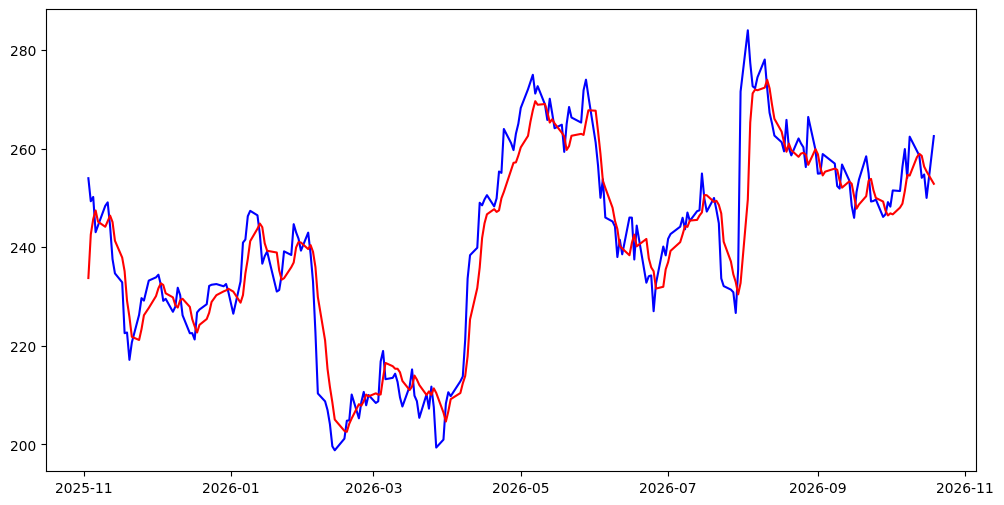

In [ ]:
# Plotting #
test_dates = df_title['Date'].values[-len(y_test):]
plt.figure(figsize=(12, 6))
plt.plot(test_dates, y_true, label="Actual", color="blue")
plt.plot(test_dates, y_pred, label="Predicted", color="red")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


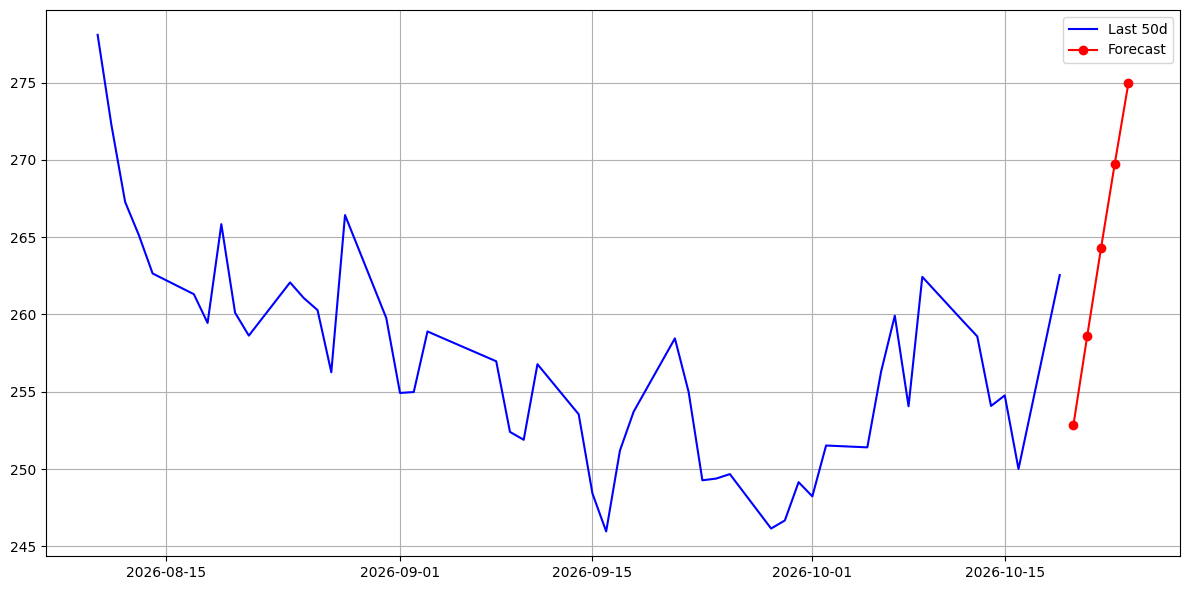

In [ ]:
# Forecast #
last_sequence = X_title[-1].copy()
forecast_scaled = []
for _ in range(FORECAST_DAYS):
  nxt_pred = float(model.predict(last_sequence[np.newaxis,:,:])[0,0])
  forecast_scaled.append(nxt_pred)
  last_sequence = np.vstack([
        last_sequence[1:],
        [nxt_pred, df_title["mean_sentiment"].iat[-1]]])

forecast_prices = scaler.inverse_transform(
  np.array(forecast_scaled).reshape(-1,1)
).flatten()

forecast_dates = []
for i in range(FORECAST_DAYS):
  forecast_dates.append(df_title["Date"].iat[-1] + datetime.timedelta(days=i+1))

plt.figure(figsize=(12,6))

plt.plot(df_title["Date"].iloc[-TIME_STEP:],
         df_title["Close"].iloc[-TIME_STEP:],
         label="Last 50d", color="blue")

plt.plot(forecast_dates, forecast_prices,
         marker="o", label="Forecast", color="red")

plt.legend(); plt.grid(); plt.tight_layout()
plt.show()